<a href="https://colab.research.google.com/github/seonilj/data-science-python-neuroscience/blob/main/assignments/task2b_spike_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How to define and detect spikes in noisy neural signals

In [6]:
import numpy as np
import matplotlib.pyplot as plt

import inspect # Part 1, 2nd code
import timeit # Part 6, 13th code


In [7]:
import sys

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. Data Loading & Audit

In [24]:
# 1. Load data
module_path = '/content/drive/MyDrive/Colab Notebooks/_utils'
if module_path not in sys.path:
    sys.path.append(module_path)

from load_neural_data import load_neural_data
print(f"🎉 Successfully imported {load_neural_data}!")

data_path = '/content/drive/MyDrive/Colab Notebooks/_data/spike_data.npz'
print(f"🎉 Successfully imported {data_path}!")

🎉 Successfully imported <function load_neural_data at 0x7d5c4a951bc0>!
🎉 Successfully imported /content/drive/MyDrive/Colab Notebooks/_data/spike_data.npz!


In [25]:
# 2. Inspect & check available arrays

print(inspect.signature(load_neural_data))
help(load_neural_data)

data = np.load(data_path)
print("Arrays:", data.files)

(file_path)
Help on function load_neural_data in module load_neural_data:

load_neural_data(file_path)

Arrays: ['t', 'raw_data']


In [27]:
# Additional: Check basic properties
t = data['t']
raw_data = data['raw_data']

print(f"t shape: {t.shape}")
print(f"raw_data shape: {raw_data.shape}")
print("-" * 20)
print(f"t data type: {t.dtype}")
print(f"raw_data type: {raw_data.dtype}")
print("-" * 20)
print(f"First time point: {t[0]}")
print(f"Last time point: {t[-1]}")

t shape: (10000,)
raw_data shape: (10000,)
--------------------
t data type: float64
raw_data type: float64
--------------------
First time point: 0.0
Last time point: 9.999


In [28]:
# 3. Sampling interval & duration & frequency
dt = np.median(np.diff(t)) # Sampling interval (not per a second, but the interval of samples)
fs = 1 / dt # Sampling frequency (초당 sample 수, Hz)

print(f"Number of samples: {len(t)}")
print(f"Recording duration (s): {len(t) / fs:.2f} s") # N samples per sec: 전체샘플/초당n개(속도)
print(f"Sampling frequency (Hz): {fs} Hz") # 1초간 측정한 샘플개수 (samples/second) = fs

Number of samples: 10000
Recording duration (s): 10.00 s
Sampling frequency (Hz): 999.9999999999991 Hz


In [29]:
# Additional: Voltage summary
print(f"Min voltage: {np.min(raw_data)}")
print(f"Max voltage: {np.max(raw_data)}")
print(f"Mean voltage: {np.mean(raw_data)}")
print(f"Median voltage: {np.median(raw_data)}")
print(f"Standard deviation: {np.std(raw_data)}")

Min voltage: -1.69098912315189
Max voltage: 6.201962575902169
Mean voltage: 0.07688186859453115
Median voltage: 0.03541220827672234
Standard deviation: 0.734406036172483


# 2. Signal Exploration

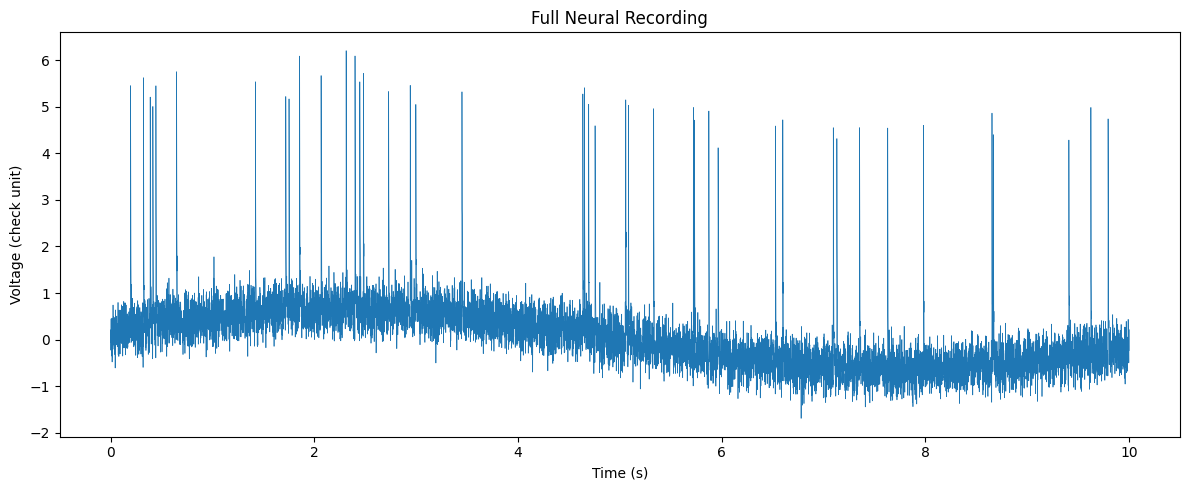

In [30]:
# 4. Visualize full recording
plt.figure(figsize=(12, 5))
plt.plot(t, raw_data, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Voltage (check unit)")
plt.title("Full Neural Recording")
plt.tight_layout()
plt.show()


Interval: 0-0.2 s
Min: -0.610
Max: 5.451
Mean: 0.290
Std: 0.600


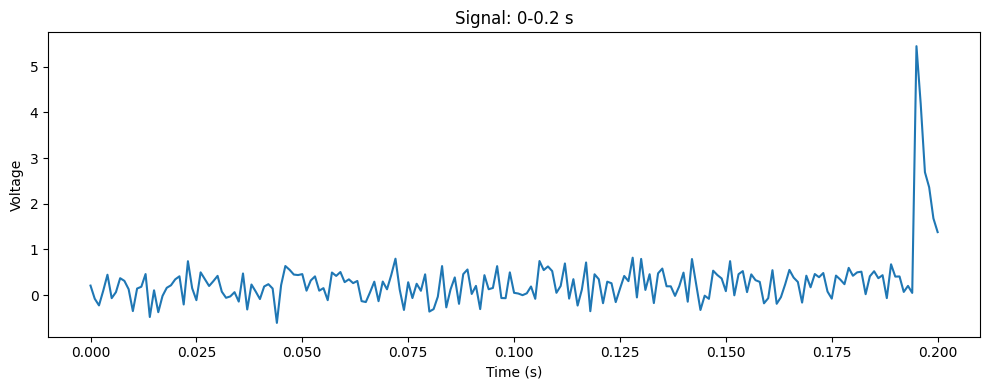


Interval: 2-2.2 s
Min: -0.031
Max: 5.667
Mean: 0.731
Std: 0.577


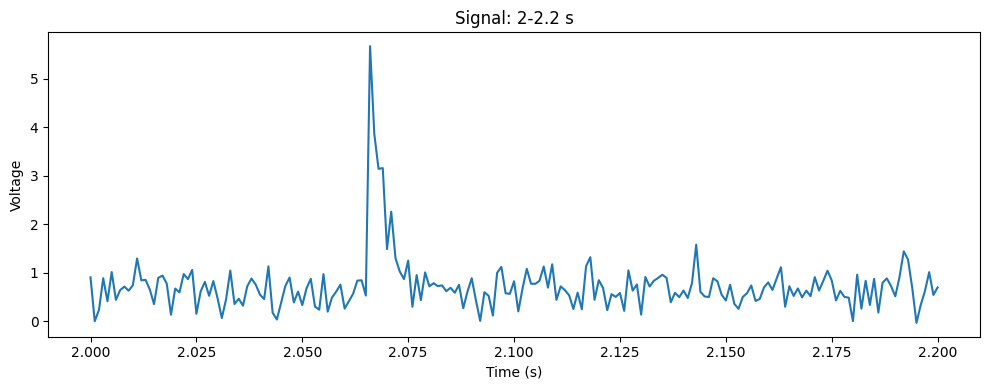


Interval: 4-4.2 s
Min: -0.697
Max: 1.209
Mean: 0.300
Std: 0.295


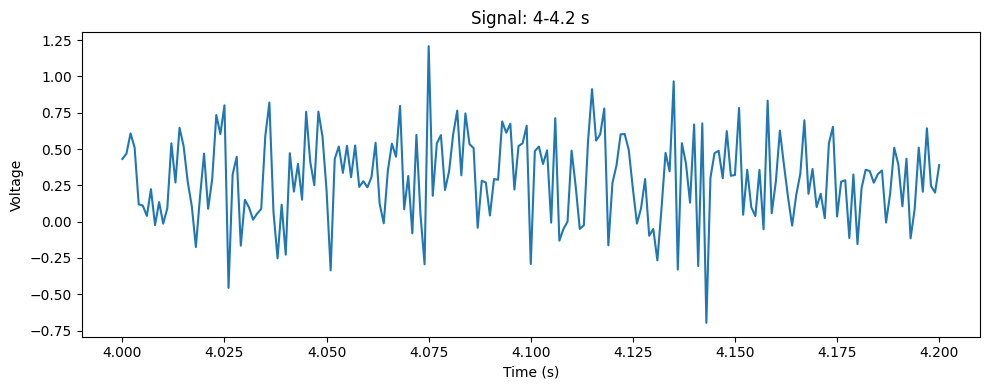


Interval: 6-6.2 s
Min: -1.267
Max: 0.404
Mean: -0.392
Std: 0.300


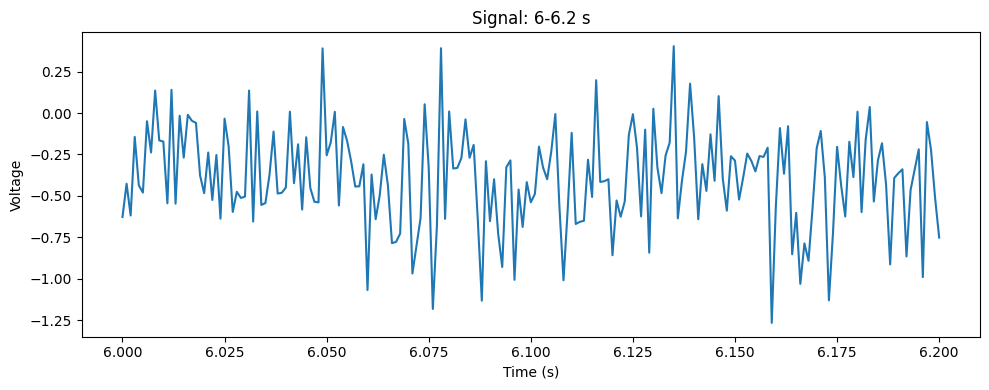


Interval: 8-8.2 s
Min: -1.275
Max: 0.093
Mean: -0.632
Std: 0.273


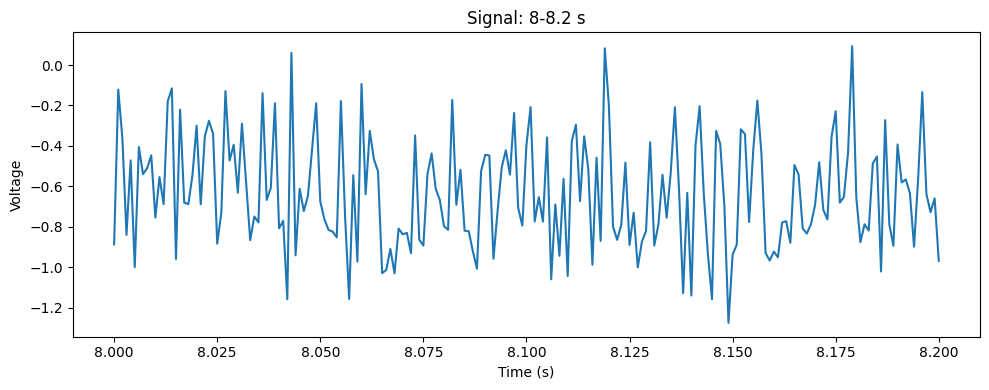

In [31]:
# 5. Inspect selected intervals
# 5.1. Full interval choice

intervals = [
    (start, start + 0.2)
    for start in np.arange(0, 10, 2)
]

for start, end in intervals:
    mask = (t >= start) & (t <= end)
    segment = raw_data[mask]

    print(f"\nInterval: {start}-{end} s")
    print(f"Min: {np.min(segment):.3f}")
    print(f"Max: {np.max(segment):.3f}")
    print(f"Mean: {np.mean(segment):.3f}")
    print(f"Std: {np.std(segment):.3f}")

    plt.figure(figsize=(10, 4))
    plt.plot(t[mask], segment)
    plt.xlabel("Time (s)")
    plt.ylabel("Voltage")
    plt.title(f"Signal: {start}-{end} s")
    plt.tight_layout()
    plt.show()


Interval: 7.5847692758484415-7.784769275848442 s
Min: -1.311
Max: 4.541
Mean: -0.573
Std: 0.590


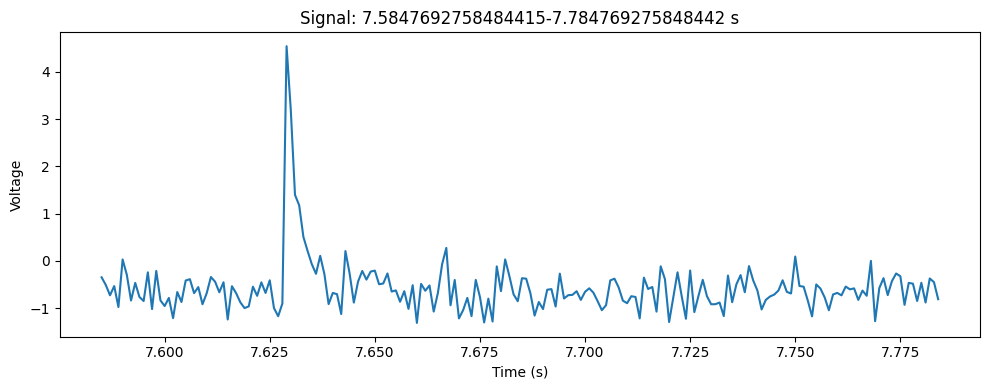


Interval: 4.301008709570113-4.5010087095701135 s
Min: -0.512
Max: 0.996
Mean: 0.186
Std: 0.305


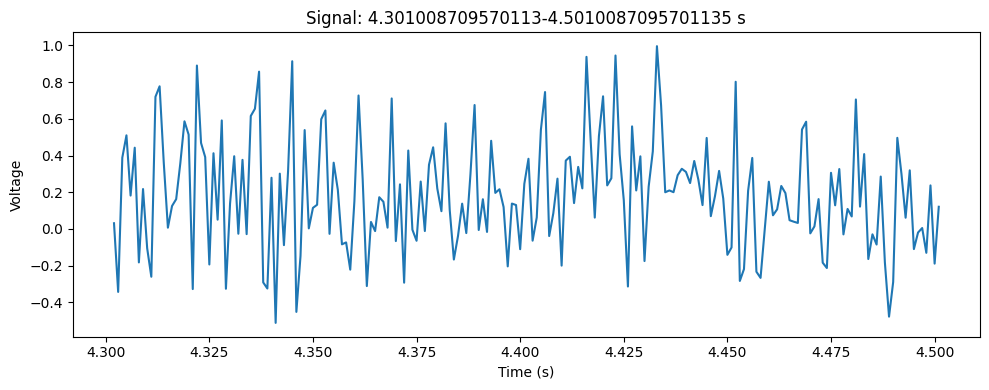


Interval: 8.414259615131549-8.614259615131548 s
Min: -1.238
Max: 0.190
Mean: -0.560
Std: 0.293


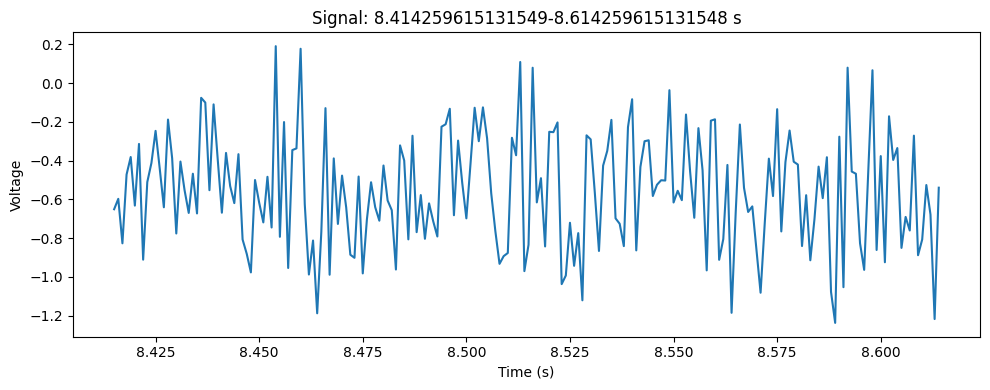


Interval: 6.834206684781766-7.034206684781767 s
Min: -1.351
Max: 0.145
Mean: -0.565
Std: 0.316


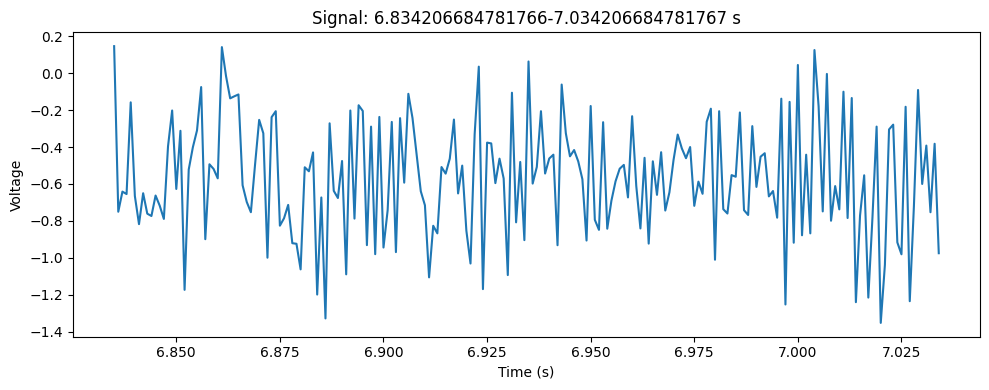


Interval: 0.9229380092989655-1.1229380092989656 s
Min: -0.373
Max: 1.776
Mean: 0.484
Std: 0.316


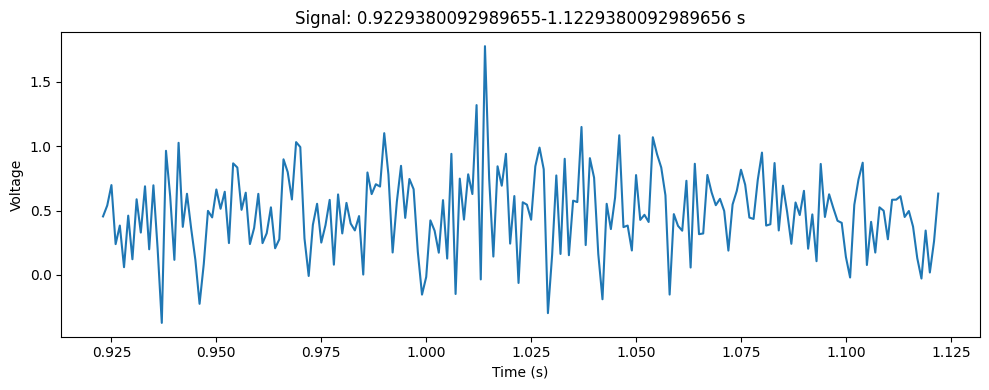

In [32]:
# 5.2. Random interval sampling

rng = np.random.default_rng(42)

starts = rng.uniform(0, 9.8, size=5)

intervals = [
    (start, start + 0.2)
    for start in starts
]

for start, end in intervals:
    mask = (t >= start) & (t <= end)
    segment = raw_data[mask]

    print(f"\nInterval: {start}-{end} s")
    print(f"Min: {np.min(segment):.3f}")
    print(f"Max: {np.max(segment):.3f}")
    print(f"Mean: {np.mean(segment):.3f}")
    print(f"Std: {np.std(segment):.3f}")

    plt.figure(figsize=(10, 4))
    plt.plot(t[mask], segment)
    plt.xlabel("Time (s)")
    plt.ylabel("Voltage")
    plt.title(f"Signal: {start}-{end} s")
    plt.tight_layout()
    plt.show()

# 3. Define Rules for the Spike


1. What makes a sample or group of samples a spike?
* The general status of neural signal is with random values of background noise. Once action potential(AP) fires, voltage rapidly increases. Therefore, the definition of a spike candidate area is defined as the samples that is over the threshold
2. How will you choose the parameters?
* Median, mean values are considered as standards, and standard deviation is also used.
3. How will you count an event only once?
* Rising Edge (transition), or 1st Boolean True is counted as one spike start because one spike will last for certain time, and also there would be refractory period, which I'd like to consider in further analysis.
4. How will you handle edge cases?
* The first sample will be handled as False value and the comparison will be started from 2nd semple in case the threshold is set too high at the very beginning.
5. How will you test your detection rule?
* The synthetic test signal can be used as a test set before confirming noisy data.

# 4. Implement and Test the Detector

In [33]:
# 6. Function to detect spikes

def detect_spikes(signal, threshold):
    """
    Function: signal & threshold as inputs, and return 'index' of where spike starts

    Parameters:
    - signal (np.ndarray): 1D voltage signal arrays
    - threshold (float): threshold to detect spikes

    Returns:
    - spike_indices (np.ndarray): Index arrays of where spike starts
    """
    # 1) Mark as T/F if bigger than threshold (Boolean Mask)
    above_thresh = signal > threshold

    if len(signal) == 0: # prevent edge samples
        return np.array([], dtype=int)

    # 2) Find 'Rising Edge': 직전 샘플 False, 현재 샘플은 True인 곳
    rising_edges = np.zeros(len(signal), dtype=bool) # shift 연산: compare before & current value

    # 1st sample (Edge case: high threshold from the start)
    rising_edges[0] = above_thresh[0]

    # 2nd-end: Now is True, right before was False
    rising_edges[1:] = above_thresh[1:] & ~above_thresh[:-1]

    # 3) Take indexes of True
    spike_indices = np.where(rising_edges)[0]

    return spike_indices

# Simple test
test_signal = np.array([1.0, 2.5, 2.5, 1.0, 3.0])
test_threshold = 2.0
result = detect_spikes(test_signal, test_threshold)
print("Detected indices:", result) # correct output: [1 4]

Detected indices: [1 4]


In [36]:
# 7. Testing Code
def run_detector_tests():
    print("---Running Spike Detector Unit Tests---\n")

    threshold = 2.0

    # Test 1: No samples above threshold (Expected result: 0)
    sig1 = np.array([1.0, 1.5, 0.5, 1.8])
    res1 = detect_spikes(sig1, threshold)
    assert len(res1) == 0, f"Test 1 Failed: Expected 0, got {len(res1)}"
    print("✅ Test 1 Passed: No samples above threshold -> 0 events")

    # Test 2: One sample above threshold (Expected result: 1)
    sig2 = np.array([1.0, 2.5, 1.0])
    res2 = detect_spikes(sig2, threshold)
    assert len(res2) == 1 and res2[0] == 1, f"Test 2 Failed"
    print("✅ Test 2 Passed: One sample -> 1 event")

    # Test 3: Several consecutive samples above threshold (Expected result: 1)
    sig3 = np.array([1.0, 2.5, 2.8, 2.2, 1.0])
    res3 = detect_spikes(sig3, threshold)
    assert len(res3) == 1 and res3[0] == 1, f"Test 3 Failed: Got {len(res3)} events"
    print("✅ Test 3 Passed: Several consecutive samples -> Counted as 1 event")

    # Test 4: Two separate above-threshold intervals (Expected result: 2)
    sig4 = np.array([1.0, 2.5, 1.0, 1.5, 3.0, 1.0])
    res4 = detect_spikes(sig4, threshold)
    assert len(res4) == 2 and res4[0] == 1 and res4[1] == 4, f"Test 4 Failed"
    print("✅ Test 4 Passed: Two separate intervals -> 2 events")

    # Test 5: Signal starts above threshold (Expected result: 0)
    # 기대 결과: 첫 번째 인덱스(0)를 올바르게 감지
    sig5 = np.array([2.5, 2.6, 1.0])
    res5 = detect_spikes(sig5, threshold)
    assert len(res5) == 1 and res5[0] == 0, f"Test 5 Failed"
    print("✅ Test 5 Passed: Signal starts above threshold -> Correctly handled at index 0")

    print("\nDone!")

# 테스트 실행
run_detector_tests()

---Running Spike Detector Unit Tests---

✅ Test 1 Passed: No samples above threshold -> 0 events
✅ Test 2 Passed: One sample -> 1 event
✅ Test 3 Passed: Several consecutive samples -> Counted as 1 event
✅ Test 4 Passed: Two separate intervals -> 2 events
✅ Test 5 Passed: Signal starts above threshold -> Correctly handled at index 0

Done!


# 5. Threshold analysis and firing-rate estimation

In [37]:
# 8. Calculate the threshold using mean + k * standard deviation

mean = np.mean(raw_data)
std = np.std(raw_data)

multipliers = [2, 3, 4]
results = []

for k in multipliers:

    threshold = mean + k * std

    spike_indices = detect_spikes(raw_data, threshold)
    spike_times = t[spike_indices]

    results.append({
        "multiplier": k,
        "threshold": threshold,
        "spike_indices": spike_indices,
        "spike_times": spike_times,
        "event_count": len(spike_indices)
    })

    print(f"k = {k}")
    print(f"Threshold: {threshold:.3f}")
    print(f"Detected events: {len(spike_indices)}")
    print("-" * 20)

k = 2
Threshold: 1.546
Detected events: 47
--------------------
k = 3
Threshold: 2.280
Detected events: 43
--------------------
k = 4
Threshold: 3.015
Detected events: 42
--------------------


In [38]:
# 9. Calculate firing rate
duration_s = len(raw_data) / fs # fs: sampling frequency

for result in results:

    event_rate = result["event_count"] / duration_s

    result["event_rate"] = event_rate

    print(
        f"k = {result['multiplier']}: "
        f"{result['event_count']} events, "
        f"{event_rate:.2f} events/s"
    )

k = 2: 47 events, 4.70 events/s
k = 3: 43 events, 4.30 events/s
k = 4: 42 events, 4.20 events/s


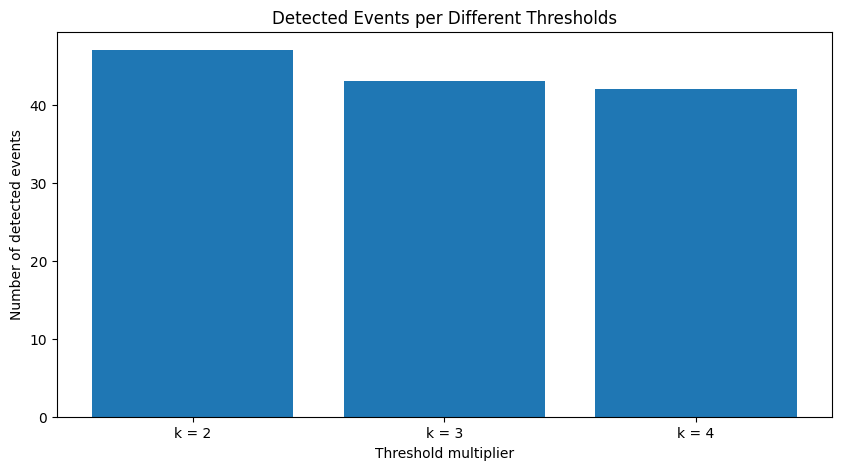

In [39]:
# 10. Visualise detected events per different threshold

labels = [f"k = {r['multiplier']}" for r in results]
counts = [r["event_count"] for r in results]

plt.figure(figsize=(10, 5))

plt.bar(labels, counts)

plt.xlabel("Threshold multiplier")
plt.ylabel("Number of detected events")
plt.title("Detected Events per Different Thresholds")

plt.show()

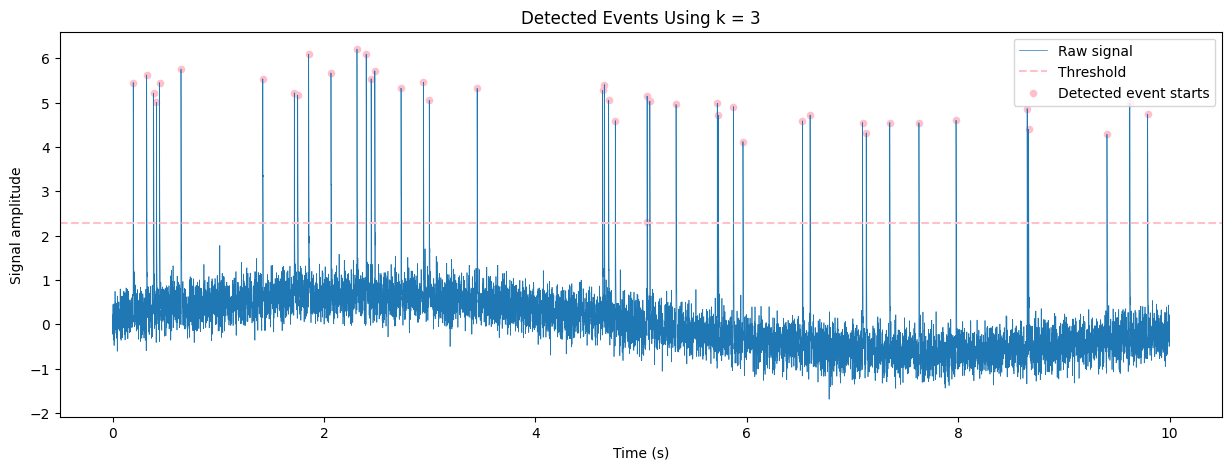

In [40]:
# 10. Visualise original signals & detected events

selected_result = results[1]  # k = 3

spike_indices = selected_result["spike_indices"]
threshold = selected_result["threshold"]

plt.figure(figsize=(15, 5))

plt.plot(t, raw_data, linewidth=0.5, label="Raw signal")

plt.axhline(
    threshold,
    color="pink",
    linestyle="--",
    label="Threshold"
)

plt.scatter(
    t[spike_indices], raw_data[spike_indices],
    color="pink",
    s=20,
    label="Detected event starts"
)

plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude")
plt.title("Detected Events Using k = 3")
plt.legend()
plt.show()

# 6. Python loop vs. NumPy vectorization

In [41]:
# 11. Python loop: Version A, Reference implementation

def detect_spikes_loop(signal, threshold):

    spike_indices = []

    i = 0

    while i < len(signal):

        if signal[i] > threshold:

            spike_indices.append(i)

            while i < len(signal) and signal[i] > threshold:
                i += 1

        else:
            i += 1

    return np.array(spike_indices, dtype=int)

In [42]:
# 12. NumPy: Version B, NumPy implementation

def detect_spikes_vectorized(signal, threshold):

    if len(signal) == 0:
        return np.array([], dtype=int)

    above_thresh = signal > threshold

    rising_edges = np.zeros(len(signal), dtype=bool)

    rising_edges[0] = above_thresh[0]

    rising_edges[1:] = above_thresh[1:] & ~above_thresh[:-1]

    spike_indices = np.where(rising_edges)[0]

    return spike_indices

In [45]:
# Result comparison of 11 and 12 codes (Python loop vs. NumPy vectorization)

threshold = mean + 3 * std

loop_result = detect_spikes_loop(raw_data, threshold)
vectorized_result = detect_spikes_vectorized(raw_data, threshold)

print("Python loop:", len(loop_result))
print("NumPy vectorized:", len(vectorized_result))

print(
    "Results are identical?",
    np.array_equal(loop_result, vectorized_result)
)

Python loop: 43
NumPy vectorized: 43
Results are identical? True


In [46]:
# 13. Compare the speed

threshold = mean + 3 * std

loop_times = timeit.repeat(
    lambda: detect_spikes_loop(raw_data, threshold),
    repeat=7,
    number=100
)

vectorized_times = timeit.repeat(
    lambda: detect_spikes_vectorized(raw_data, threshold),
    repeat=7,
    number=100
)

loop_median = np.median(loop_times) / 100

vectorized_median = np.median(vectorized_times) / 100

speedup = loop_median / vectorized_median # = loop execution time / vectorized execution time

print(f"Version A, Python loop: {loop_median * 1000:.4f} ms")
print(f"Version B, Vectorized: {vectorized_median * 1000:.4f} ms")
print(f"Speedup: {speedup:.2f}x")

Version A, Python loop: 2.1680 ms
Version B, Vectorized: 0.0126 ms
Speedup: 172.50x
